# 🎯 Modul 9 — Praktikum Statistik Deskriptif & EDA

### Reference Walkthrough: Mall Customers Dataset + Milestone 1 Template

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS · CPMK072 Dimulai

---

## 🎯 Tujuan Pembelajaran

1. **Menghitung** measures of central tendency (mean, median, modus) dan memilih yang tepat.
2. **Menghitung** measures of dispersion (variance, std, IQR, CV, range).
3. **Membuat** visualisasi univariat & bivariat untuk eksplorasi data.
4. **Menerapkan** framework EDA 7-langkah pada dataset Kaggle pilihan sendiri.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Mall Customers | 5 menit |
| **B** | Inspeksi Awal & Data Quality | 10 menit |
| **C** | Central Tendency (mean/median/mode) | 10 menit |
| **D** | Dispersion (std/var/IQR/CV) | 10 menit |
| **E** | Univariate Visualization | 15 menit |
| **F** | Bivariate Visualization | 15 menit |
| **G** | Interactive Plotly Dashboard | 10 menit |
| **H** | Milestone 1 Template + Refleksi | 15 menit |

**Total: ± 90 menit**

---

## 💡 Mengapa Mall Customers?

- ✅ **200 pelanggan nyata** sebuah mall di Amerika
- ✅ Mix of types: 1 nominal (Gender) + 4 numeric (ID, Age, Income, Spending Score)
- ✅ Dataset klasik Kaggle untuk EDA + customer segmentation
- ✅ Insight bisnis nyata: pola belanja per gender, age-income-spending relationship
- ✅ Template langsung bisa diaplikasikan ke dataset pilihan mahasiswa

**Catatan**: Dataset ini adalah **REFERENSI**. Milestone 1 Anda harus memilih dataset Kaggle SENDIRI (≥500 rows, ≥5 kolom) dan apply framework yang sama.


---

# 🔧 A. Setup & Load Mall Customers


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load Mall Customers dataset
url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv"
df = pd.read_csv(url)

# Rename for easier access
df.rename(columns={
    'Genre': 'Gender',
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'SpendingScore'
}, inplace=True)

print(f"Dataset berhasil dimuat!")
print(f"Shape: {df.shape[0]} baris × {df.shape[1]} kolom")
df.head()


Dataset berhasil dimuat!
Shape: 200 baris × 5 kolom


,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


---

# 🔍 B. Inspeksi Awal & Data Quality


In [22]:
# Step 1: dtypes & missing values
print("=== DATA TYPES ===")
print(df.dtypes)
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
print("\n=== DUPLICATE ROWS ===")
print(f"Duplikat: {df.duplicated().sum()}")
print("\n=== MEMORY USAGE ===")
print(df.memory_usage(deep=True).sum(), "bytes")


=== DATA TYPES ===
CustomerID        int64
Gender           object
Age               int64
Income            int64
SpendingScore     int64
dtype: object

=== MISSING VALUES ===
CustomerID       0
Gender           0
Age              0
Income           0
SpendingScore    0
dtype: int64

=== DUPLICATE ROWS ===
Duplikat: 0

=== MEMORY USAGE ===
17356 bytes


In [23]:
# Step 2: Statistik deskriptif ringkasan (otomatis via describe)
print("=== DESCRIBE NUMERIC ===")
df.describe().round(2)


=== DESCRIBE NUMERIC ===


,CustomerID,Age,Income,SpendingScore
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [24]:
# Describe categorical (Gender)
print("=== DESCRIBE CATEGORICAL ===")
df['Gender'].value_counts()


=== DESCRIBE CATEGORICAL ===


,count
Gender,
Female,112
Male,88


---

# 📊 C. Measures of Central Tendency

**Tujuan Pembelajaran 1** — Mean, Median, Modus per kolom numerik.


In [25]:
# Pilih kolom numerik (kecuali CustomerID)
numeric_cols = ['Age', 'Income', 'SpendingScore']

central = pd.DataFrame({
    'Mean': df[numeric_cols].mean().round(2),
    'Median': df[numeric_cols].median().round(2),
    'Modus': df[numeric_cols].mode().iloc[0].round(2),
    'Diff (Mean-Median)': (df[numeric_cols].mean() - df[numeric_cols].median()).round(2),
})

print("CENTRAL TENDENCY per kolom numerik:\n")
print(central)
print("\n💡 Jika Mean > Median → right-skewed")
print("   Jika Mean < Median → left-skewed")
print("   Jika Mean ≈ Median → symmetric")


CENTRAL TENDENCY per kolom numerik:

                Mean  Median  Modus  Diff (Mean-Median)
Age            38.85    36.0   32.0                2.85
Income         60.56    61.5   54.0               -0.94
SpendingScore  50.20    50.0   42.0                0.20

💡 Jika Mean > Median → right-skewed
   Jika Mean < Median → left-skewed
   Jika Mean ≈ Median → symmetric


In [26]:
# Interpretasi otomatis
print("INTERPRETASI DISTRIBUSI:")
for col in numeric_cols:
    mean = df[col].mean()
    median = df[col].median()
    diff = (mean - median) / median * 100
    if abs(diff) < 2:
        shape = "SYMMETRIC (dekat Normal)"
    elif diff > 0:
        shape = f"RIGHT-SKEWED (mean {diff:.1f}% > median)"
    else:
        shape = f"LEFT-SKEWED (mean {diff:.1f}% < median)"
    print(f"  {col:<15}: {shape}")

# Modus untuk Gender (categorical)
print(f"\nModus Gender: {df['Gender'].mode()[0]} ({df['Gender'].value_counts().iloc[0]} orang)")


INTERPRETASI DISTRIBUSI:
  Age            : RIGHT-SKEWED (mean 7.9% > median)
  Income         : SYMMETRIC (dekat Normal)
  SpendingScore  : SYMMETRIC (dekat Normal)

Modus Gender: Female (112 orang)


---

# 📏 D. Measures of Dispersion

**Tujuan Pembelajaran 2** — Variance, Std, IQR, CV.


In [27]:
dispersion = pd.DataFrame({
    'Range': df[numeric_cols].max() - df[numeric_cols].min(),
    'Variance': df[numeric_cols].var().round(2),
    'Std Dev': df[numeric_cols].std().round(2),
    'Q1': df[numeric_cols].quantile(0.25),
    'Q3': df[numeric_cols].quantile(0.75),
    'IQR': df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    'CV (%)': (df[numeric_cols].std() / df[numeric_cols].mean() * 100).round(2),
})

print("DISPERSION per kolom numerik:\n")
print(dispersion)
print("\n💡 CV tinggi = variasi relatif besar (bagus untuk bandingkan antar kolom)")
print("   IQR = robust terhadap outlier")


DISPERSION per kolom numerik:

               Range  Variance  Std Dev     Q1    Q3    IQR  CV (%)
Age               52    195.13    13.97  28.75  49.0  20.25   35.96
Income           122    689.84    26.26  41.50  78.0  36.50   43.37
SpendingScore     98    666.85    25.82  34.75  73.0  38.25   51.44

💡 CV tinggi = variasi relatif besar (bagus untuk bandingkan antar kolom)
   IQR = robust terhadap outlier


In [28]:
# Interpretasi CV
print("INTERPRETASI COEFFICIENT OF VARIATION (CV):")
for col in numeric_cols:
    cv = df[col].std() / df[col].mean() * 100
    if cv < 15:
        level = "RENDAH — data cukup konsisten"
    elif cv < 30:
        level = "SEDANG — variasi wajar"
    else:
        level = "TINGGI — variasi besar antar observasi"
    print(f"  {col:<15}: CV = {cv:.1f}% → {level}")


INTERPRETASI COEFFICIENT OF VARIATION (CV):
  Age            : CV = 36.0% → TINGGI — variasi besar antar observasi
  Income         : CV = 43.4% → TINGGI — variasi besar antar observasi
  SpendingScore  : CV = 51.4% → TINGGI — variasi besar antar observasi


---

# 📊 E. Univariate Visualization

**Tujuan Pembelajaran 3** — Histogram, boxplot, violin, countplot.


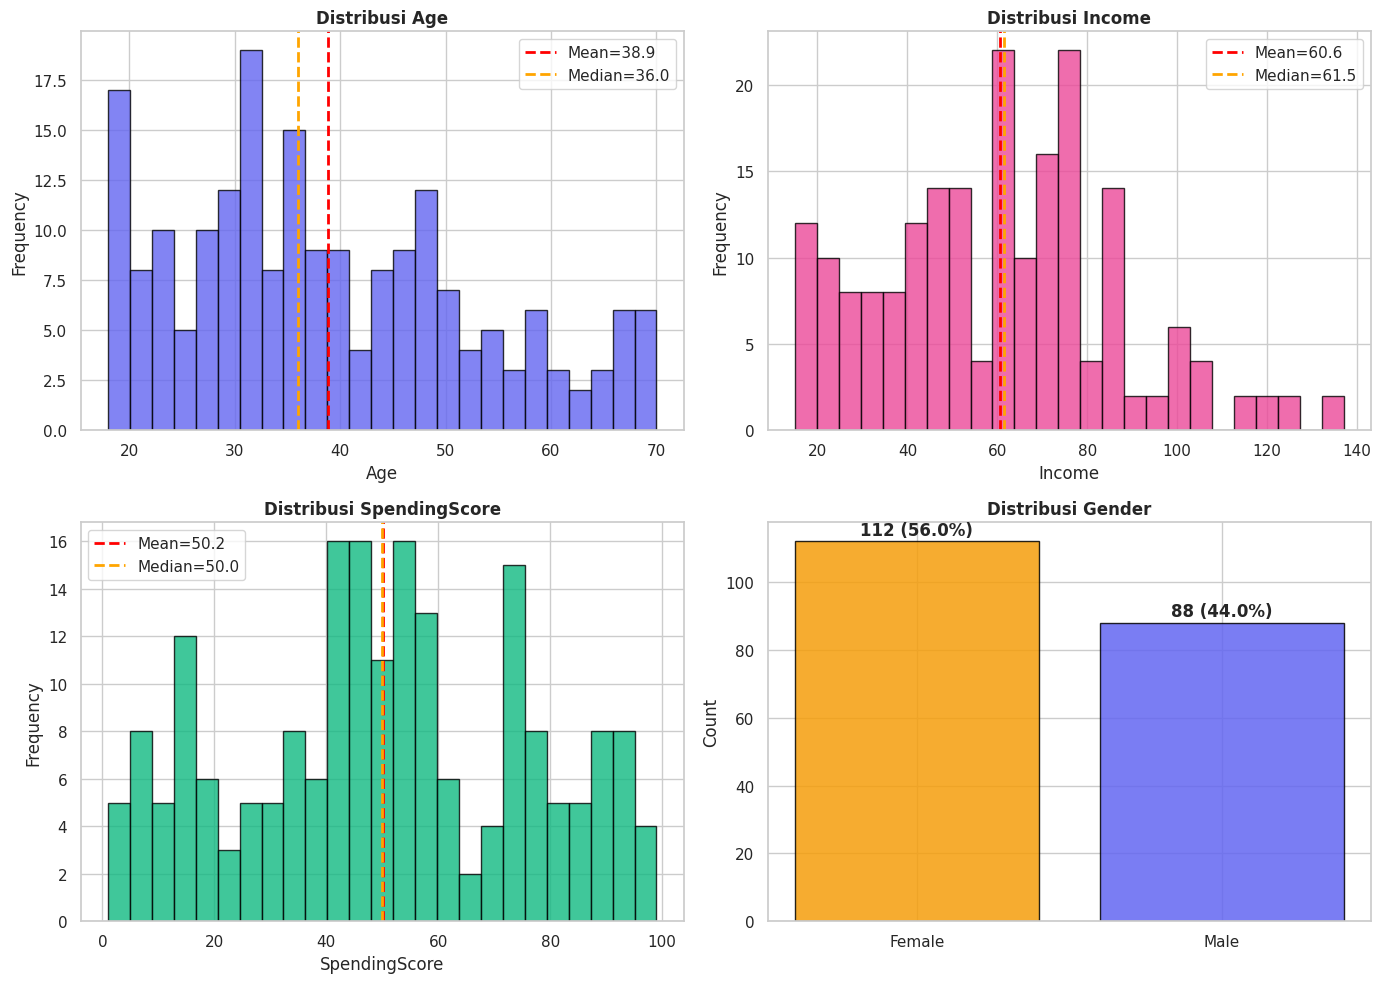

In [29]:
# 2x2 grid: histogram untuk 3 numerik + countplot gender
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col, color in zip(axes.flatten()[:3], numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    df[col].hist(bins=25, ax=ax, color=color, edgecolor='black', alpha=0.8)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=2, label=f'Median={df[col].median():.1f}')
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

# Gender countplot
ax = axes[1, 1]
counts = df['Gender'].value_counts()
bars = ax.bar(counts.index, counts.values, color=['#F59E0B', '#6366F1'], edgecolor='black', alpha=0.85)
ax.set_title('Distribusi Gender', fontweight='bold')
ax.set_ylabel('Count')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f'{val} ({val/len(df)*100:.1f}%)', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


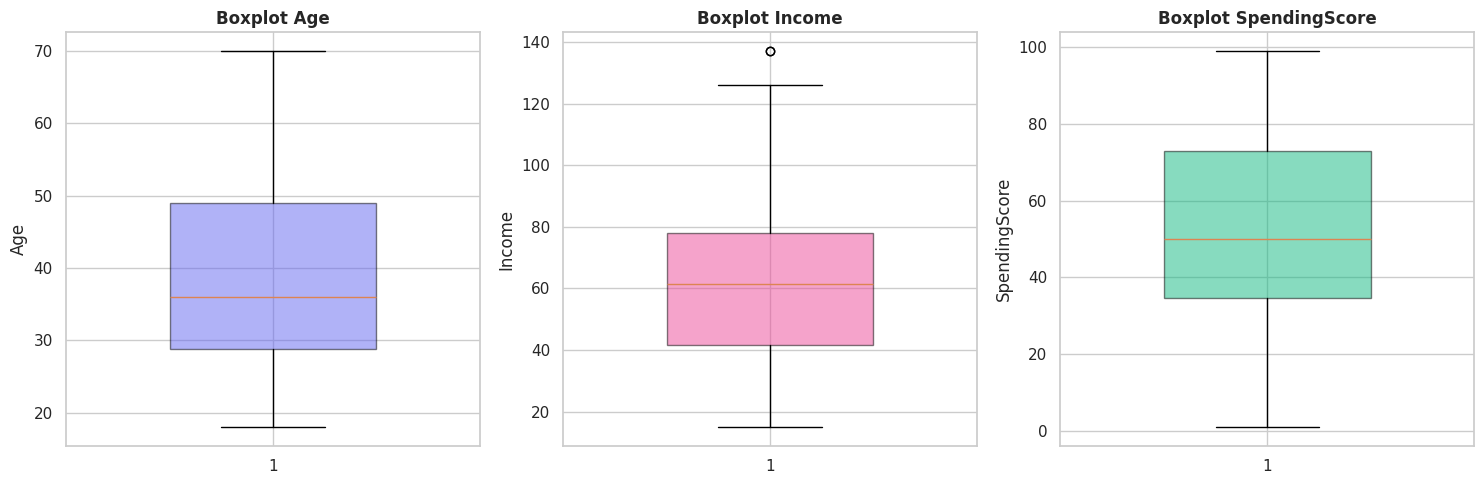


=== DETEKSI OUTLIER (IQR method) ===
  Age            : 0 outlier (<-1.6 atau >79.4)
  Income         : 2 outlier (<-13.2 atau >132.8)
  SpendingScore  : 0 outlier (<-22.6 atau >130.4)


In [30]:
# Boxplot untuk deteksi outlier
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    bp = ax.boxplot(df[col], patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor(color)
    bp['boxes'][0].set_alpha(0.5)
    ax.set_title(f'Boxplot {col}', fontweight='bold')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# Deteksi outlier via IQR
print("\n=== DETEKSI OUTLIER (IQR method) ===")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f"  {col:<15}: {len(outliers)} outlier (<{Q1-1.5*IQR:.1f} atau >{Q3+1.5*IQR:.1f})")


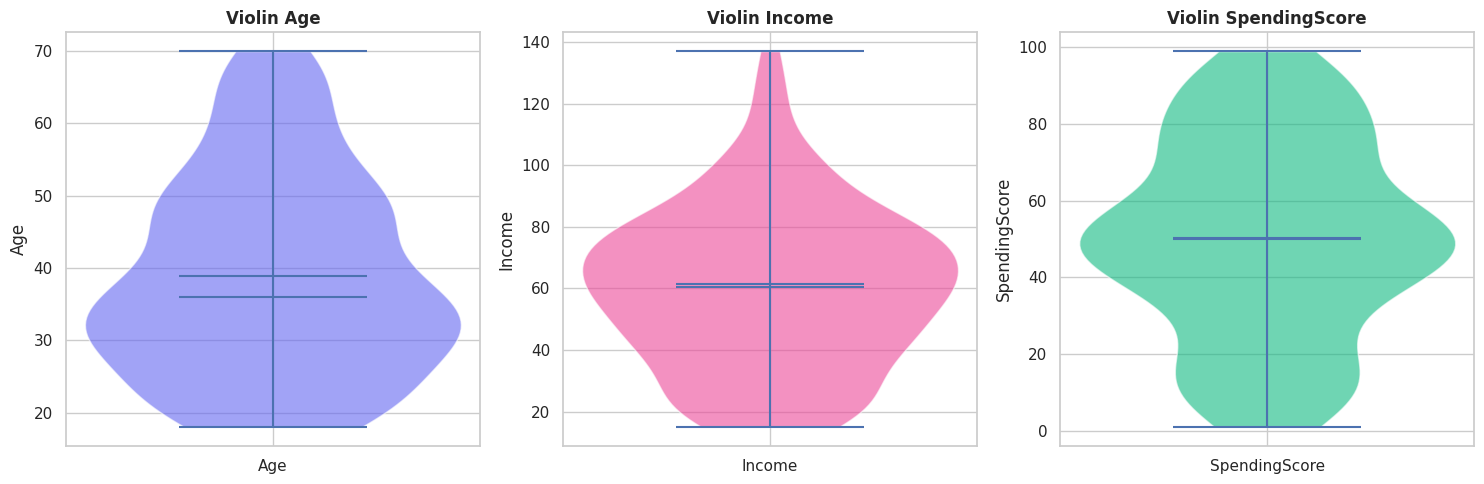

In [31]:
# Violin plot — distribusi + density
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, ['#6366F1', '#EC4899', '#10B981']):
    parts = ax.violinplot(df[col], widths=0.6, showmeans=True, showmedians=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.6)
    ax.set_title(f'Violin {col}', fontweight='bold')
    ax.set_ylabel(col)
    ax.set_xticks([1])
    ax.set_xticklabels([col])

plt.tight_layout()
plt.show()


---

# 🔗 F. Bivariate Visualization

**Tujuan Pembelajaran 3** — Scatter, correlation heatmap, pair plot, grouped boxplot.


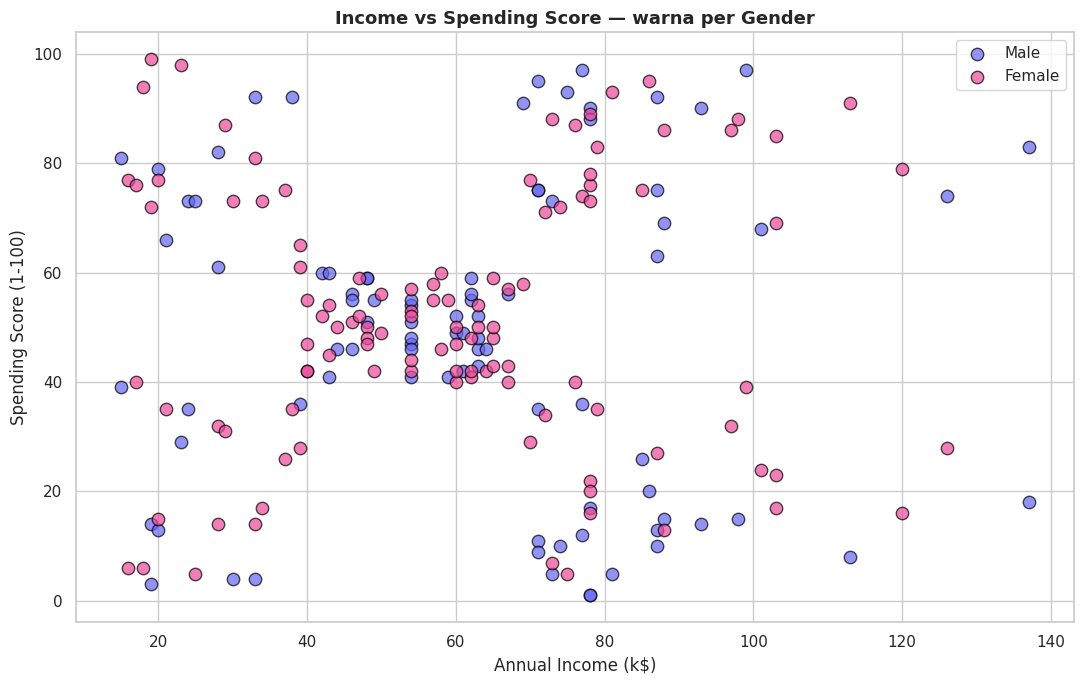


💡 Visual terlihat 5 cluster alami — ini landasan customer segmentation!


In [32]:
# Scatter: Income vs SpendingScore (dengan warna Gender)
fig, ax = plt.subplots(figsize=(11, 7))
for gender, color in [('Male', '#6366F1'), ('Female', '#EC4899')]:
    sub = df[df['Gender'] == gender]
    ax.scatter(sub['Income'], sub['SpendingScore'], c=color, label=gender, s=80, alpha=0.7, edgecolors='black')

ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Income vs Spending Score — warna per Gender', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Visual terlihat 5 cluster alami — ini landasan customer segmentation!")


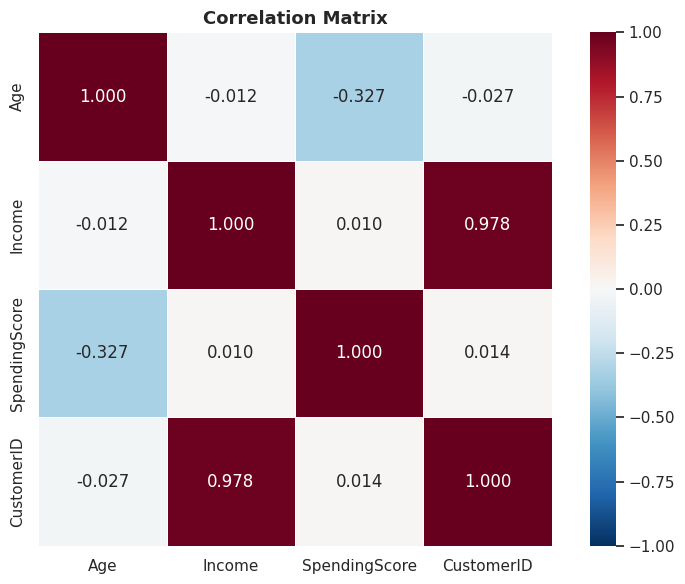


💡 PENTING: CustomerID korelasi 0.978 dengan Income — ini artifact karena data diurutkan!
   Drop CustomerID sebelum analisis lanjut.


In [33]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[numeric_cols + ['CustomerID']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("\n💡 PENTING: CustomerID korelasi 0.978 dengan Income — ini artifact karena data diurutkan!")
print("   Drop CustomerID sebelum analisis lanjut.")


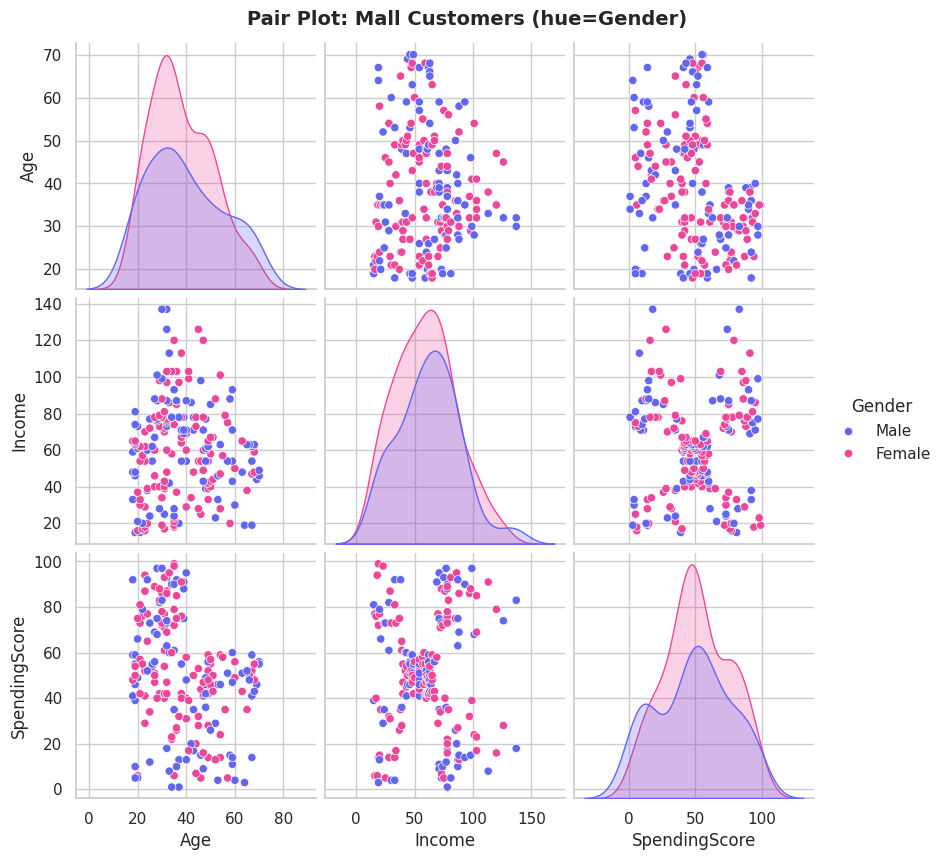

In [34]:
# Pair plot — scatter matrix semua pasangan numerik
g = sns.pairplot(df[numeric_cols + ['Gender']], hue='Gender',
                 palette={'Male': '#6366F1', 'Female': '#EC4899'},
                 diag_kind='kde', height=2.8)
g.fig.suptitle('Pair Plot: Mall Customers (hue=Gender)', y=1.02, fontsize=14, fontweight='bold')
plt.show()


/tmp/ipykernel_2960/3313872228.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_2960/3313872228.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_2960/3313872228.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




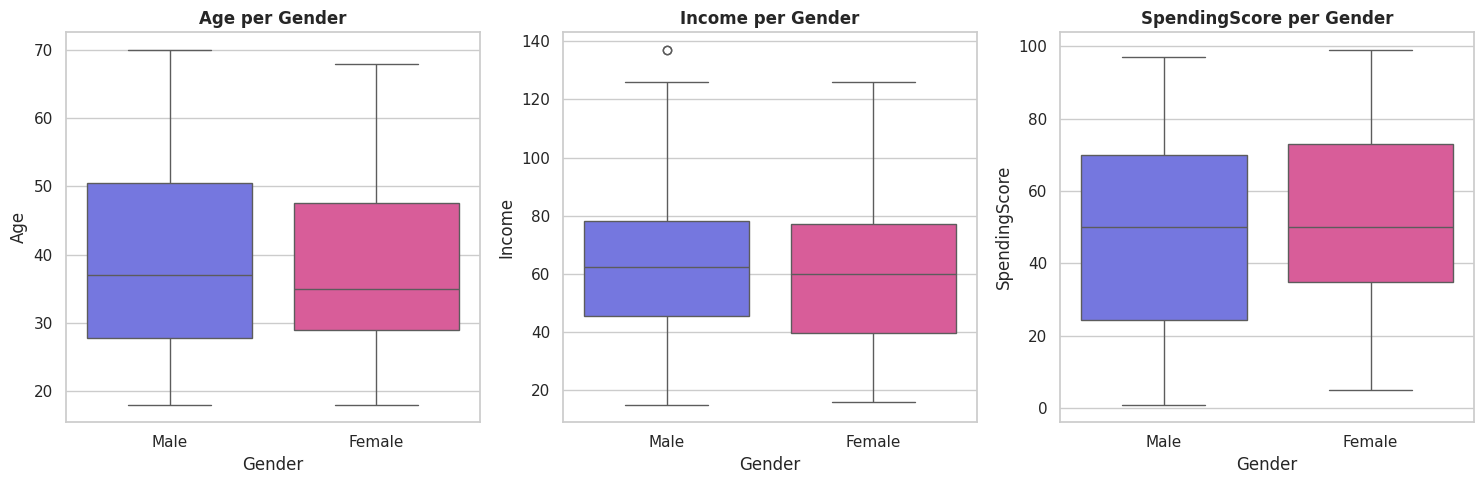


=== PERBANDINGAN MEAN per GENDER ===
          Age  Income  SpendingScore
Gender                              
Female  38.10   59.25          51.53
Male    39.81   62.23          48.51


In [35]:
# Grouped boxplot: bandingkan metric per Gender
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x='Gender', y=col, data=df, ax=ax,
                palette={'Male': '#6366F1', 'Female': '#EC4899'})
    ax.set_title(f'{col} per Gender', fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical comparison
print("\n=== PERBANDINGAN MEAN per GENDER ===")
print(df.groupby('Gender')[numeric_cols].mean().round(2))


---

# 📊 G. Interactive Plotly Dashboard

**Tujuan Pembelajaran 4** — Dashboard interactive siap-share.


In [36]:
# Interactive scatter dengan hover info
fig = px.scatter(df, x='Income', y='SpendingScore',
                 color='Gender', size='Age',
                 hover_data=['CustomerID', 'Age'],
                 title='Mall Customers: Income vs Spending Score (interaktif)',
                 color_discrete_map={'Male': '#6366F1', 'Female': '#EC4899'},
                 size_max=25)
fig.update_layout(width=900, height=500, font=dict(size=12))
fig.show()


In [37]:
# Multi-panel dashboard
fig = make_subplots(rows=2, cols=2,
                    subplot_titles=('Distribusi Age', 'Distribusi Income',
                                    'Distribusi Spending Score', 'Gender Breakdown'),
                    specs=[[{'type':'histogram'}, {'type':'histogram'}],
                           [{'type':'histogram'}, {'type':'pie'}]])

fig.add_trace(go.Histogram(x=df['Age'], marker_color='#6366F1', nbinsx=25), row=1, col=1)
fig.add_trace(go.Histogram(x=df['Income'], marker_color='#EC4899', nbinsx=25), row=1, col=2)
fig.add_trace(go.Histogram(x=df['SpendingScore'], marker_color='#10B981', nbinsx=25), row=2, col=1)

counts = df['Gender'].value_counts()
fig.add_trace(go.Pie(labels=counts.index, values=counts.values,
                     marker=dict(colors=['#EC4899', '#6366F1'])), row=2, col=2)

fig.update_layout(height=700, width=1000, showlegend=False,
                  title_text='Mall Customers Interactive Dashboard',
                  title_font_size=16)
fig.show()


---

# 📝 H. Milestone 1 Template + Refleksi

## H.1 Insight dari Mall Customers (Reference)

Dari EDA di atas, berikut 5 insight bisnis yang bisa diambil:

1. **Gender Balance**: 56% Female, 44% Male — sedikit skew ke perempuan.
2. **Age Distribusi**: slight right-skewed (mean 38.9 > median 36), rentang 18-70 tahun.
3. **Income vs Spending TIDAK ada korelasi linier** (r ≈ 0.01) — insight kunci untuk segmentasi.
4. **5 cluster alami terlihat di scatter Income vs Spending** → landasan K-Means (M12+).
5. **Spending Score simetris** (mean=median=50) — mungkin skor dirancang dengan normalisasi.

## H.2 Template Milestone 1 untuk Dataset Anda

Setelah menyelesaikan reference di atas, buat notebook baru untuk dataset pilihan Anda:


Library berhasil diimport!
Shape: (10841, 13)
Missing Values:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Total Missing Values:
1487

Duplicates:
Jumlah data duplikat: 483

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           1084

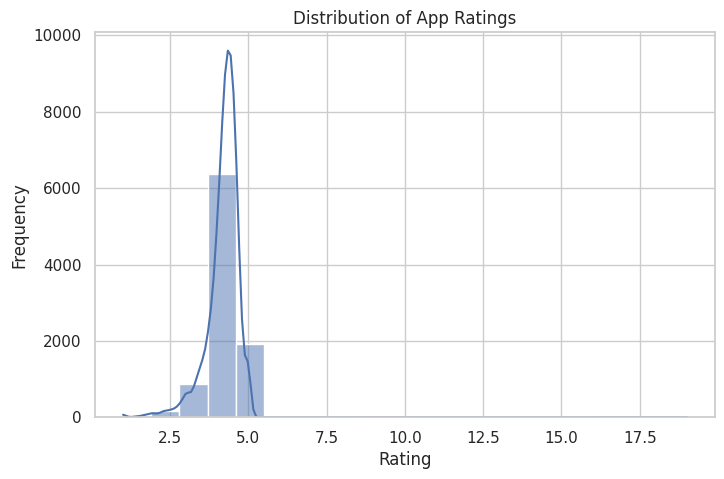

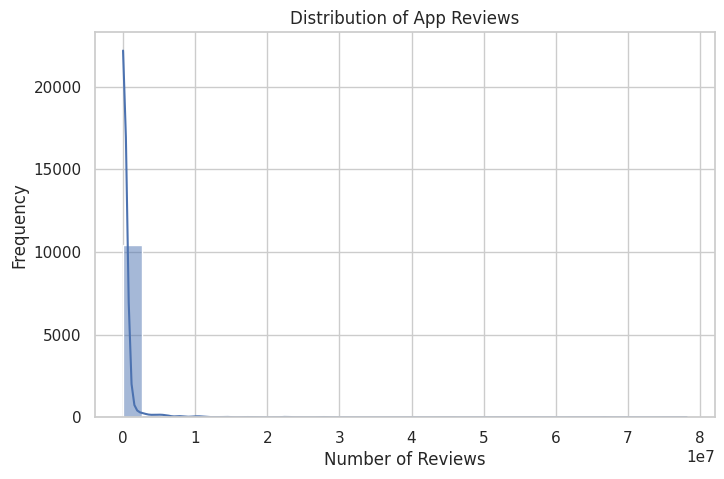

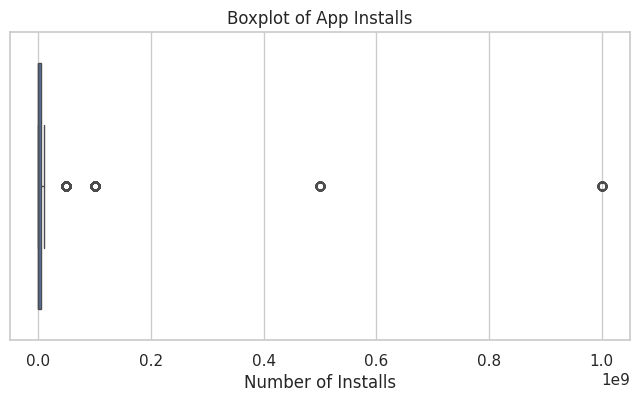

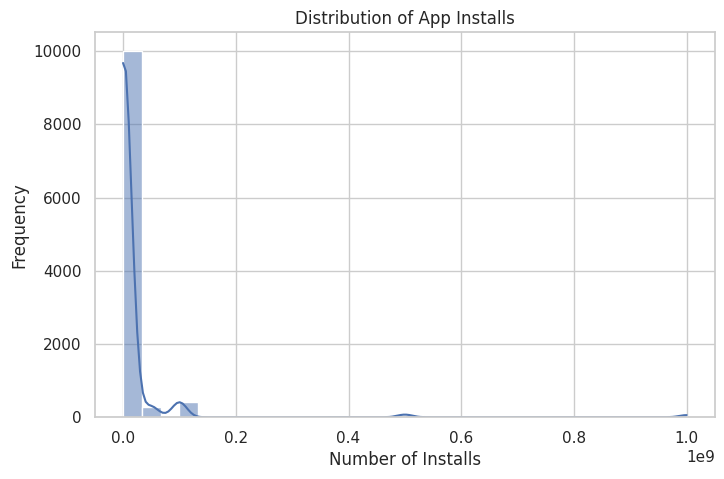

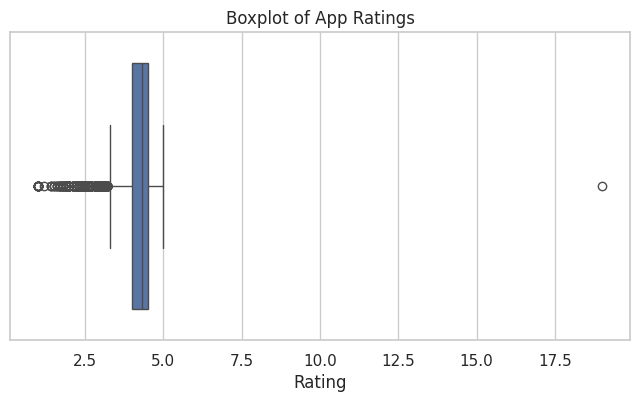

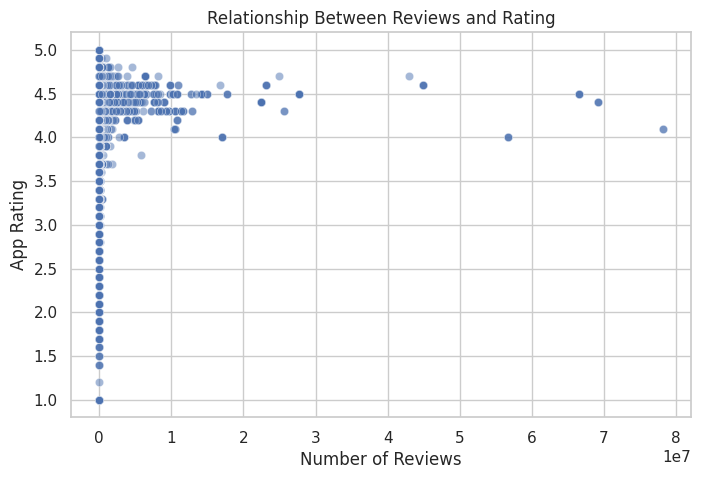

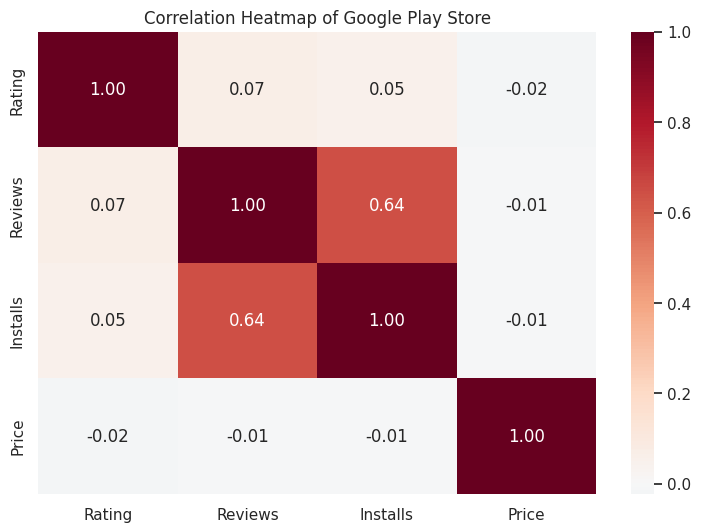

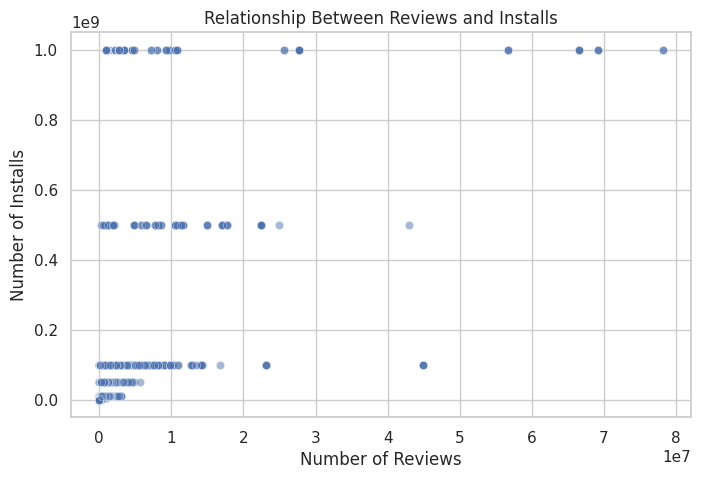

💡 Copy template ini ke notebook baru, ganti URL dan nama kolom.
   Submit sebelum Modul 10 dimulai (link GitHub via LMS).


In [40]:
# =========================================================
# TEMPLATE MILESTONE 1 — ganti URL dengan dataset Anda
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Library berhasil diimport!")
# STEP 1: Load Dataset
df_my = pd.read_csv("googleplaystore.csv")
print(f"Shape: {df_my.shape}")
df_my.head()

# STEP 2: Missing & Duplicate Check
print("Missing Values:")
print(df_my.isnull().sum())

print("\nTotal Missing Values:")
print(df_my.isnull().sum().sum())

print("\nDuplicates:")
print(f"Jumlah data duplikat: {df_my.duplicated().sum()}")

print("\nInformasi Dataset:")
df_my.info()

# STEP 3: Central Tendency
df_my['Reviews'] = pd.to_numeric(df_my['Reviews'], errors='coerce')

df_my['Installs'] = (
    df_my['Installs']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)

df_my['Installs'] = pd.to_numeric(df_my['Installs'], errors='coerce')

df_my['Price'] = (
    df_my['Price']
    .astype(str)
    .str.replace('$', '', regex=False)
)

df_my['Price'] = pd.to_numeric(df_my['Price'], errors='coerce')

numeric = df_my.select_dtypes(include='number').columns.tolist()

print("Kolom Numerik:")
print(numeric)

print("\nStatistik Deskriptif:")
print(df_my[numeric].describe())

print("\nMean:")
print(df_my[numeric].mean())

print("\nMedian:")
print(df_my[numeric].median())

print("\nModus:")
print(df_my[numeric].mode().iloc[0])

# STEP 4: Dispersion
dispersion = {}

for c in numeric:
    mean_value = df_my[c].mean()
    std_value = df_my[c].std()

    dispersion[c] = {
        'Variance': df_my[c].var(),
        'Std': std_value,
        'IQR': df_my[c].quantile(0.75) - df_my[c].quantile(0.25),
        'CV': (std_value / mean_value * 100) if mean_value != 0 else np.nan
    }

dispersion_df = pd.DataFrame(dispersion).T

print(dispersion_df)

# STEP 5: Univariate Viz — min 3 histogram/boxplot
# Histogram Rating
plt.figure(figsize=(8, 5))
sns.histplot(df_my['Rating'].dropna(), bins=20, kde=True)
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()
# Histogram Reviews
plt.figure(figsize=(8, 5))
sns.histplot(df_my['Reviews'].dropna(), bins=30, kde=True)
plt.title('Distribution of App Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Frequency')
plt.show()
# Boxplot Installs
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_my['Installs'])
plt.title('Boxplot of App Installs')
plt.xlabel('Number of Installs')
plt.show()
# Histogram Installs
plt.figure(figsize=(8, 5))
sns.histplot(df_my['Installs'].dropna(), bins=30, kde=True)
plt.title('Distribution of App Installs')
plt.xlabel('Number of Installs')
plt.ylabel('Frequency')
plt.show()
# Boxplot Rating
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_my['Rating'])
plt.title('Boxplot of App Ratings')
plt.xlabel('Rating')
plt.show()

# STEP 6: Bivariate Viz — min scatter + heatmap
# Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_my,
    x='Reviews',
    y='Rating',
    alpha=0.5
)

plt.title('Relationship Between Reviews and Rating')
plt.xlabel('Number of Reviews')
plt.ylabel('App Rating')
plt.show()
# Heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    df_my[numeric].corr(),
    annot=True,
    cmap='RdBu_r',
    center=0,
    fmt='.2f'
)

plt.title('Correlation Heatmap of Google Play Store')
plt.show()
# Bivariate Visualization 3: Reviews vs Installs

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_my,
    x='Reviews',
    y='Installs',
    alpha=0.5
)

plt.title('Relationship Between Reviews and Installs')
plt.xlabel('Number of Reviews')
plt.ylabel('Number of Installs')
plt.show()
# =========================================================
# STEP 7: PLOTLY INTERACTIVE DASHBOARD
# =========================================================

import plotly.express as px

# Grafik 1: 10 Kategori Aplikasi Terbanyak
top_category = (
    df_my['Category']
    .value_counts()
    .head(10)
    .reset_index()
)

top_category.columns = ['Category', 'Total Apps']

fig1 = px.bar(
    top_category,
    x='Category',
    y='Total Apps',
    title='Top 10 Categories by Number of Apps',
    color='Total Apps',
    text='Total Apps'
)

fig1.update_layout(
    xaxis_title='App Category',
    yaxis_title='Number of Apps'
)

fig1.show()


# Grafik 2: Hubungan Reviews dan Installs
fig2 = px.scatter(
    df_my.dropna(subset=['Reviews', 'Installs']),
    x='Reviews',
    y='Installs',
    color='Type',
    hover_data=['App', 'Category'],
    title='Relationship Between Reviews and Installs',
    opacity=0.6
)

fig2.update_layout(
    xaxis_title='Number of Reviews',
    yaxis_title='Number of Installs'
)

fig2.show()

# STEP 7: 3-5 Insight tertulis (markdown cell)
# - Insight 1: ...
# - Insight 2: ...
# - Insight 3: ...

print("💡 Copy template ini ke notebook baru, ganti URL dan nama kolom.")
print("   Submit sebelum Modul 10 dimulai (link GitHub via LMS).")


EDA Insights — Google Play Store Apps
1. Kualitas Dataset

Dataset Google Play Store terdiri dari 10.841 baris dan 13 kolom. Berdasarkan pemeriksaan data, ditemukan 1.487 nilai kosong dan 483 data duplikat. Hal ini menunjukkan bahwa dataset masih memiliki beberapa masalah kualitas data yang perlu diperhatikan sebelum analisis lebih lanjut.

2. Rating Aplikasi

Rata-rata rating aplikasi sebesar 4,19, sedangkan mediannya sebesar 4,3. Hal ini menunjukkan bahwa sebagian besar aplikasi memiliki rating yang cukup tinggi. Namun, terdapat nilai maksimum 19 yang tidak sesuai dengan skala rating Google Play Store sehingga perlu diperiksa lebih lanjut.

3. Jumlah Reviews

Rata-rata jumlah ulasan aplikasi sebesar 444.152, sedangkan mediannya hanya 2.094. Perbedaan yang cukup besar ini menunjukkan bahwa distribusi jumlah ulasan tidak merata dan terdapat beberapa aplikasi dengan jumlah ulasan yang sangat tinggi.

4. Jumlah Installs

Rata-rata jumlah instalasi aplikasi sekitar 15,46 juta, sedangkan mediannya sebesar 100 ribu. Hal ini menunjukkan bahwa tingkat popularitas aplikasi sangat bervariasi dan hanya sebagian aplikasi yang memiliki jumlah instalasi sangat tinggi.

5. Harga Aplikasi

Median dan modus harga aplikasi adalah 0. Hal ini menunjukkan bahwa aplikasi gratis mendominasi dataset Google Play Store dibandingkan aplikasi berbayar.

Hipotesis 1: Hubungan Reviews dan Installs
- H0: Tidak terdapat hubungan yang signifikan antara jumlah ulasan (Reviews) dan jumlah instalasi (Installs) aplikasi.
- H1: Terdapat hubungan yang signifikan antara jumlah ulasan (Reviews) dan jumlah instalasi (Installs) aplikasi.
Hipotesis 2: Perbedaan Rating Aplikasi Gratis dan Berbayar
- H0: Tidak terdapat perbedaan rata-rata rating antara aplikasi gratis dan aplikasi berbayar.
- H1: Terdapat perbedaan rata-rata rating antara aplikasi gratis dan aplikasi berbayar.
Hipotesis 3: Hubungan Rating dan Installs
- H0: Tidak terdapat hubungan yang signifikan antara rating aplikasi dan jumlah instalasi.
- H1: Terdapat hubungan yang signifikan antara rating aplikasi dan jumlah instalasi.

## H.3 Pertanyaan Refleksi

Jawab 5 pertanyaan berikut di cell markdown di bawah:

1. **Mean vs Median**: Pada kolom Income Mall Customers, mean=60.6 dan median=61.5 — hampir sama. Jelaskan apa artinya untuk bentuk distribusi dan implikasi pada pemilihan ukuran pemusatan.

2. **CustomerID artifact**: Korelasi CustomerID dengan Income adalah 0.978 — bukan karena ID "menyebabkan" Income tinggi, tapi karena data terurut. Sebutkan 1 contoh lain dari "spurious correlation" di dunia nyata dan bahayanya.

3. **IQR vs Std Dev**: Kapan Anda memilih IQR dibanding Std Dev untuk melaporkan sebaran data? Berikan contoh kasus nyata.

4. **5 Cluster Natural**: Pada scatter Income vs Spending Score, visual menunjukkan 5 kelompok. Apa strategi bisnis mall jika terbukti ada 5 segmen? Berikan minimal 1 contoh.

5. **Dataset Milestone 1**: Dataset apa yang Anda pilih untuk Milestone 1? Jelaskan sumber, konteks bisnis, dan 3 pertanyaan yang ingin Anda jawab melalui EDA.

### ✏️ Jawaban Anda:

**1.** Mean dan median pada kolom Income memiliki nilai yang hampir sama, yaitu 60,6 dan 61,5. Hal ini menunjukkan bahwa distribusi data cenderung simetris dan tidak memiliki kemencengan yang terlalu besar. Dalam kondisi seperti ini, mean dan median sama-sama dapat digunakan sebagai ukuran pemusatan data. Namun, median lebih tepat digunakan jika terdapat outlier karena tidak mudah dipengaruhi oleh nilai ekstrem.

**2.** Contoh spurious correlation dalam kehidupan nyata adalah hubungan antara penjualan es krim dengan jumlah kasus tenggelam. Keduanya mungkin meningkat secara bersamaan saat musim panas, tetapi bukan berarti es krim menyebabkan orang tenggelam. Faktor cuaca panas menjadi penyebab yang memengaruhi keduanya. Bahayanya adalah kita bisa mengambil kesimpulan yang salah jika hanya melihat hubungan korelasi tanpa memahami penyebab sebenarnya.

**3.** IQR lebih tepat digunakan ketika data memiliki outlier atau distribusi yang tidak normal karena IQR hanya memperhatikan rentang 50% data bagian tengah. Sedangkan standar deviasi lebih cocok untuk data yang distribusinya relatif normal dan tidak memiliki banyak nilai ekstrem. Contohnya adalah data pendapatan masyarakat, karena biasanya terdapat beberapa orang dengan pendapatan sangat tinggi yang dapat memengaruhi standar deviasi.

**4.** Jika mall memiliki lima segmen pelanggan, pihak mall dapat membuat strategi pemasaran yang berbeda untuk setiap kelompok. Contohnya, pelanggan dengan pendapatan tinggi dan pengeluaran tinggi dapat diberikan penawaran produk premium dan program VIP. Sementara itu, pelanggan dengan pendapatan rendah dapat diberikan diskon atau promo khusus agar tertarik berbelanja. Dengan begitu, strategi pemasaran menjadi lebih tepat sasaran.

**5.** Dataset yang saya pilih adalah Google Play Store Apps Dataset yang diperoleh dari Kaggle. Dataset ini berisi informasi aplikasi Android, seperti nama aplikasi, kategori, rating, jumlah ulasan, ukuran aplikasi, jumlah instalasi, tipe aplikasi, harga, dan versi Android.

Konteks bisnis dari dataset ini adalah menganalisis perkembangan aplikasi pada Google Play Store untuk mengetahui karakteristik aplikasi yang diminati pengguna serta faktor yang dapat memengaruhi popularitas aplikasi.

Tiga pertanyaan yang ingin saya jawab melalui EDA:
1. Kategori aplikasi apa yang memiliki jumlah aplikasi paling banyak?
2. Apakah rating aplikasi berhubungan dengan jumlah instalasi?
3. Apakah aplikasi berbayar memiliki rating yang berbeda dibandingkan aplikasi gratis?


## H.4 Checklist Submit Milestone 1

### Reference Walkthrough (notebook ini):
- [ ] Semua cell sukses dijalankan tanpa error
- [ ] Central tendency table muncul lengkap
- [ ] Dispersion table muncul lengkap
- [ ] Histogram + boxplot + violin + countplot muncul
- [ ] Scatter + heatmap + pairplot muncul
- [ ] Plotly dashboard interaktif
- [ ] 5 pertanyaan refleksi dijawab

### Milestone 1 Deliverable (notebook SENDIRI):
- [ ] Dataset Kaggle pilihan (≥500 rows, ≥5 kolom, bukan Mall Customers)
- [ ] Framework EDA 7-langkah lengkap
- [ ] Minimal 6 visualisasi (3 univariat + 3 bivariat)
- [ ] 1 interactive Plotly dashboard (minimal 2 chart)
- [ ] 3-5 insight tertulis dengan evidence
- [ ] Daftar 2-3 hipotesis untuk Milestone 2 (M10 hypothesis testing)
- [ ] README.md dengan: deskripsi dataset, sumber, cara menjalankan, ringkasan insight
- [ ] Repo GitHub ter-commit dan link dikumpulkan via LMS

### Deadline: SEBELUM pertemuan Modul 10 dimulai.

## H.5 Push ke GitHub

1. Buat repository baru: `projek-statistika-<nama>` di GitHub
2. Upload notebook, README, dan screenshot dashboard
3. Commit message: `"Milestone 1: EDA dataset <nama-dataset>"`
4. Submit link repo via LMS Uniska

---

## 🎓 Selamat! Anda Berhasil...

✅ Menghitung semua measures of central tendency dan dispersion
✅ Membuat 6 jenis visualisasi berbeda
✅ Membangun interactive Plotly dashboard
✅ Mengekstrak 5 insight bisnis dari dataset
✅ Siap aplikasi ke Milestone 1 dengan dataset pilihan sendiri

## 📚 Bacaan Lanjutan

- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Chapter 1 (Exploratory Data Analysis).
- **Tukey, J.** (1977). *Exploratory Data Analysis* — pionir boxplot & five-number summary.
- **Plotly Documentation** — interactive dashboards: https://plotly.com/python/
- **Seaborn Gallery** — https://seaborn.pydata.org/examples/

## 🔮 Persiapan Modul 10

Modul 10 — **Inferential Statistics & Hypothesis Testing**:
- Confidence Interval (CI 95%)
- t-test, chi-square, ANOVA
- p-value interpretation
- **Milestone 2**: Uji 2-3 hipotesis yang Anda formulasikan di akhir M9

**Sebelum M10:**
1. Selesaikan Milestone 1 EDA, push ke GitHub
2. Formulasikan 3 hipotesis dari insight Milestone 1 Anda
3. Baca Bruce Ch. 3 (Statistical Experiments and Significance Testing)

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
